# Open-set individual re-identification from photos (photo-ID)

Camera traps and photo-ID surveys monitor animals that carry **individual
markings** — spots, stripes, scars, scute or scale patterns. Two questions are
asked of a batch of new photos (the *queries*):

1. **Which known individual is this?** Each query is compared with a labelled
   **reference set** (the *gallery*, a catalogue of animals identified in
   earlier seasons). This is *closed-set* matching.
2. **How many individuals are there?** Some queries show animals that are not
   in the catalogue. They must be grouped among themselves, without labels.
   This is *open-set* discovery, and the number of groups is the **abundance**
   estimate used in capture–recapture.

Both questions are answered by **one partition of the query images**: images
with the same label are the same animal. The quality of that partition is
measured with the **adjusted Rand index** (ARI; 1 = perfect, ≈0 = chance)
and the **relative abundance error** $|\hat K - K| / K$.

This tutorial uses `ov.tl.reid_*`, a toolbox for the whole chain:

| Step | Function | What it does |
|---|---|---|
| descriptor | `load_reid_backbone` | an animal re-ID network (MiewID, MegaDescriptor) or any timm / Hugging Face model, with its evaluation transform |
| | `reid_embed` | batched CPU embedding (optional flip / crop views, cache file), L2-normalised |
| | `reid_pair_auc` | how well a similarity separates same-individual from different-individual pairs |
| | `reid_fuse_similarity` | put several similarity matrices on one scale and average them |
| | `reid_view_center` | remove the mean shift between viewpoints / camera modes |
| | `reid_fit_projection` | reference-supervised linear metric (PCA + LDA), validated on held-out individuals |
| verification | `reid_candidate_pairs` | top-*k* retrieval pairs from the global similarity |
| | `reid_local_verify` | SIFT/ORB keypoints + ratio test + RANSAC, with a random-pair null for the acceptance cut |
| partition | `reid_select_threshold` | choose the clustering cut by simulation on the labelled reference |
| | `reid_open_set_cluster` | attach queries to gallery identities, cluster the rest; every cut chosen from data |
| all of it | `reid_pipeline` | one call per image subset; each optional step kept only if it helps on held-out reference individuals |

## Principle

**Global descriptor.** A network maps image $x_i$ to a unit vector
$f_i$; the similarity of two photos is the cosine $s_{ij} = f_i^\top f_j$.
Its usefulness for re-ID is the probability that a same-individual pair is
more similar than a different-individual pair,

$$\mathrm{AUC} = P\big(s_{ij} > s_{kl} \mid y_i = y_j,\ y_k \neq y_l\big).$$

Generic (ImageNet) features describe the *scene* — species, pose, light,
background — and give an AUC near 0.5 for individuals of one species. Re-ID
backbones are trained to ignore those factors: **MiewID** (multi-species, trained
on fine individual markings) and **MegaDescriptor** (Swin transformers trained on
dozens of wildlife re-ID datasets).

**Local geometric verification.** A spot pattern is (nearly) planar, so two
photos of the same flank are related by a homography $H$. SIFT keypoints are
matched by nearest descriptor and kept if the best match is clearly better
than the second best (Lowe's ratio test, $d_1/d_2 < \rho$, $\rho = 0.75$);
RANSAC then finds the $H$ with the most inliers
$\lVert x'_m - H x_m \rVert < \varepsilon$. Different individuals produce only a
handful of accidental inliers. Instead of a hand-chosen inlier count, the cut
is calibrated on a **null**: the same matcher is run on random pairs (almost all
of them different animals), and a candidate pair is accepted when

$$n_\text{inliers} > c = \max\big(m,\ Q_{0.995}(\text{null inliers})\big).$$

Only the top-*k* global neighbours of each query are verified, so the cost is
$O(nk)$ rather than $O(n^2)$.

**Viewpoint centring.** If a camera mode (day colour vs night infra-red) shifts
all embeddings of that mode, $e' = e + \lambda(\mu - \mu_v)$ moves each
mode's mean $\mu_v$ towards the global mean $\mu$ ($\lambda = 0.5$).

**Open-set partition.** For query $i$ and gallery individual $c$ the identity
score is the mean of the top-2 similarities to the images of $c$. Queries (or
whole query clusters) whose best score exceeds an *attach cut* $a$ take that
identity; the rest are clustered by average-linkage at a *cluster cut* $t$;
verified pairs are forced together (must-links). $a$ and $t$ are chosen by
**simulation on the reference**: the labelled gallery is split into a
pseudo-gallery and a pseudo-query set shaped like the real one (same size,
half of the individuals unseen), and the cut maximising

$$\mathrm{ARI} - 0.25\,\frac{|\hat K - K|}{K}$$

is used for the real queries. Without a reference, accepted verified pairs act
as pseudo-labels: half of them are forced together and the partition is scored
by pairwise F1 on the other half.

In [1]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from sklearn.metrics import adjusted_rand_score, silhouette_score

import omicverse as ov
ov.plot_set(ipython_format='png')

T0 = time.time()
DATA = "reid_demo"                      # everything this notebook writes goes here
IMG = os.path.join(DATA, "images")
CACHE = os.path.join(DATA, "cache")
os.makedirs(CACHE, exist_ok=True)

🔬 Starting plot initialization...
🧬 Detecting GPU devices…
🚫 No GPU devices found (CUDA/MPS/ROCm/XPU)

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.3.2   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



## 1. A simulated population with known identities

Real photo-ID sets cannot be redistributed freely here, and they rarely come
with a complete truth for *every* query. So we render one ourselves. Each
animal of one (fictional) spotted species has the same body shape and fur
colour; **only the spot layout is individual** (45–70 dark ellipses at random
positions, sizes and orientations). Each photo (*sighting*) is rendered with

- a random **pose**: rotation ±25°, scale 0.7–1.05, shear, mild perspective,
  and a jittered position (the animal is roughly centred, as after a detector
  crop);
- one of four **camera sites**, each with its own background of bushes and
  trunks (a random window of the site picture);
- foreground **grass** occluding the animal in half of the photos;
- a **light** gradient and gain, sensor noise, occasional blur;
- a **camera mode**: 30 % of the photos are night infra-red shots (grey,
  flat, noisier). This is the *view* label.

The **gallery** holds 24 catalogued individuals × 3 photos. The **query**
batch holds 1–3 new photos of 14 of those individuals and 1–3 photos of 14
individuals never seen before.

In [2]:
H, W = 240, 320            # photo size (px)
BH, BW = 150, 230          # animal canvas (px)


def make_site(rng, size=(360, 440)):
    """A camera site: sky/ground gradient, bushes and trunks in site colours."""
    h, w = size
    top, bot = rng.uniform(60, 200, 3), rng.uniform(30, 140, 3)
    t = np.linspace(0, 1, h)[:, None, None]
    img = (top * (1 - t) + bot * t) * np.ones((1, w, 1))
    for _ in range(rng.integers(10, 16)):                      # bushes
        c = tuple(int(v) for v in rng.uniform(20, 200, 3))
        cv2.ellipse(img, (int(rng.uniform(0, w)), int(rng.uniform(h * .3, h))),
                    (int(rng.uniform(25, 90)), int(rng.uniform(15, 60))),
                    float(rng.uniform(0, 180)), 0, 360, c, -1)
    for _ in range(rng.integers(2, 5)):                        # trunks
        x = int(rng.uniform(0, w))
        c = tuple(int(v) for v in rng.uniform(20, 120, 3))
        cv2.line(img, (x, 0), (x + int(rng.uniform(-40, 40)), h), c, int(rng.uniform(8, 25)))
    return np.clip(cv2.GaussianBlur(img, (0, 0), 1.5), 0, 255).astype(np.float32)


def body_mask():
    """The species' silhouette: torso, head, four legs, tail (same for everyone)."""
    m = np.zeros((BH, BW), np.uint8)
    cv2.ellipse(m, (115, 70), (80, 38), 0, 0, 360, 255, -1)
    cv2.ellipse(m, (200, 52), (24, 20), -15, 0, 360, 255, -1)
    for x in (60, 85, 145, 170):
        cv2.rectangle(m, (x - 7, 90), (x + 7, 145), 255, -1)
    cv2.line(m, (38, 60), (8, 95), 255, 8)
    return m


def make_coat(rng):
    """One individual: species fur colour + its own random spot pattern."""
    base = np.array([150, 185, 215], np.float32) + rng.normal(0, 6, 3)      # BGR, tan
    coat = np.ones((BH, BW, 3), np.float32) * base
    for _ in range(int(rng.integers(45, 70))):
        c = (int(rng.uniform(0, BW)), int(rng.uniform(0, BH)))
        ax = (int(rng.uniform(3, 9)), int(rng.uniform(2, 7)))
        cv2.ellipse(coat, c, ax, float(rng.uniform(0, 180)), 0, 360,
                    tuple(float(v) for v in base * rng.uniform(0.15, 0.45)), -1)
    return coat


def photo(coat, mask, site, rng, night=False):
    """One sighting: pose, position, background window, occlusion, light, camera mode."""
    sh, sw = site.shape[:2]
    y0, x0 = int(rng.uniform(0, sh - H)), int(rng.uniform(0, sw - W))
    bg = site[y0:y0 + H, x0:x0 + W].copy()
    A = cv2.getRotationMatrix2D((BW / 2, BH / 2), rng.uniform(-25, 25), rng.uniform(0.7, 1.05))
    A[0, 1] += rng.uniform(-0.12, 0.12)                                    # shear
    A[:, 2] += [(W - BW) / 2 + rng.uniform(-15, 15), (H - BH) / 2 + rng.uniform(-12, 12)]
    P = np.vstack([A, [rng.uniform(-3e-4, 3e-4), rng.uniform(-3e-4, 3e-4), 1.0]])
    animal = cv2.warpPerspective(coat, P, (W, H))
    m = cv2.warpPerspective(mask, P, (W, H)).astype(np.float32) / 255.0
    m = cv2.GaussianBlur(m, (0, 0), 1.0)[..., None]
    img = animal * m + bg * (1 - m)
    if rng.random() < 0.5:                                                 # grass in front
        for _ in range(int(rng.integers(3, 8))):
            x = int(rng.uniform(0, W))
            c = tuple(float(v) for v in rng.uniform(30, 120, 3))
            cv2.line(img, (x, H), (x + int(rng.uniform(-30, 30)), int(rng.uniform(H * .3, H * .7))),
                     c, int(rng.integers(2, 5)))
    xx = np.arange(W)[None, :]
    img = img * (rng.uniform(0.7, 1.25) * (1 + rng.uniform(-0.25, 0.25) * (xx / W - 0.5)))[..., None]
    if night:                                                              # IR flash
        grey = cv2.cvtColor(np.clip(img, 0, 255).astype(np.uint8), cv2.COLOR_BGR2GRAY)
        img = np.repeat((0.6 * grey.astype(np.float32) + 60)[..., None], 3, -1)
    img = img + rng.normal(0, 8 if night else 4, img.shape)
    if rng.random() < 0.3:
        img = cv2.GaussianBlur(img, (0, 0), 0.8)
    return np.clip(img, 0, 255).astype(np.uint8)


def simulate(outdir, n_known=24, n_known_seen=14, n_new=14, n_ref=3, max_sightings=3,
             n_sites=4, p_night=0.3, seed=0):
    rng = np.random.default_rng(seed)
    os.makedirs(outdir, exist_ok=True)
    sites = [make_site(rng) for _ in range(n_sites)]
    mask = body_mask()
    rows = []
    for i in range(n_known + n_new):
        coat = make_coat(rng)
        known = i < n_known
        if known:
            sets = [("reference", n_ref)]
            if i < n_known_seen:
                sets.append(("query", int(rng.integers(1, max_sightings + 1))))
        else:
            sets = [("query", int(rng.integers(1, max_sightings + 1)))]
        for split, k in sets:
            for j in range(k):
                s, night = int(rng.integers(n_sites)), bool(rng.random() < p_night)
                f = f"{split}_{i:02d}_{j}.jpg"
                cv2.imwrite(os.path.join(outdir, f), photo(coat, mask, sites[s], rng, night),
                            [cv2.IMWRITE_JPEG_QUALITY, 92])
                rows.append((f, split, f"animal{i:02d}", known, s, "night" if night else "day"))
    return pd.DataFrame(rows, columns=["path", "split", "identity", "known", "site", "view"])


meta = simulate(IMG)
g = meta[meta.split == "reference"].reset_index(drop=True)     # labelled gallery
q = meta[meta.split == "query"].reset_index(drop=True)         # queries (truth hidden from the methods)
K_TRUE = q.identity.nunique()
print(f"gallery: {len(g)} photos of {g.identity.nunique()} individuals")
print(f"queries: {len(q)} photos of {K_TRUE} individuals "
      f"({q[q.known].identity.nunique()} catalogued, {q[~q.known].identity.nunique()} new)")
print("sightings per query individual:", q.identity.value_counts().value_counts().sort_index().to_dict())

gallery: 72 photos of 24 individuals
queries: 56 photos of 28 individuals (14 catalogued, 14 new)
sightings per query individual: {1: 12, 2: 4, 3: 12}


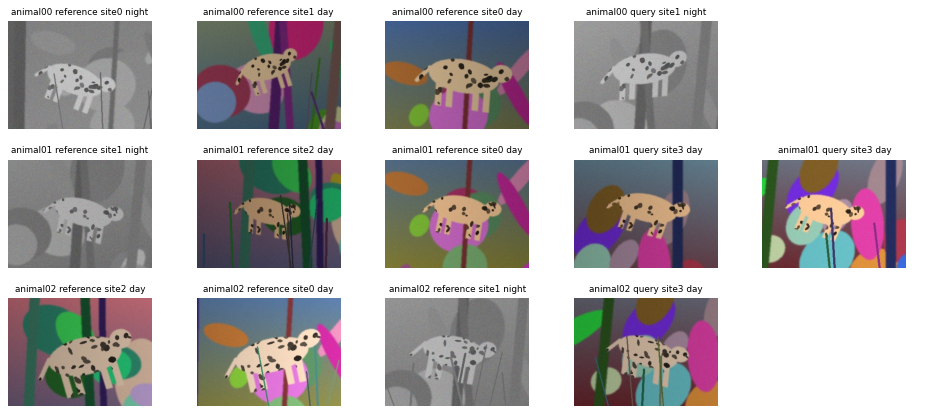

In [3]:
def show(path, ax, title=""):
    ax.imshow(cv2.cvtColor(cv2.imread(os.path.join(IMG, path)), cv2.COLOR_BGR2RGB))
    ax.set_title(title, fontsize=8)
    ax.axis("off")

who = ["animal00", "animal01", "animal02"]
fig, axes = plt.subplots(3, 5, figsize=(12, 5.4))
for r, ind in enumerate(who):
    rows = meta[meta.identity == ind].head(5)
    for c in range(5):
        if c < len(rows):
            x = rows.iloc[c]
            show(x.path, axes[r, c], f"{ind} {x.split} site{x.site} {x.view}")
        else:
            axes[r, c].axis("off")
plt.tight_layout()
plt.show()

Each row is one individual. Its spot layout is the only stable cue; site,
pose, occlusion and camera mode change from photo to photo — and photos of
*different* animals at the same site share most of their pixels.

## 2. Descriptors: a re-ID backbone and a generic one

`load_reid_backbone` knows the short names `"miewid"` (Hugging Face
`conservationxlabs/miewid-msv3`, 512 px input) and `"megadescriptor-l"` /
`"-b"` / `"-s"` / `"-t"` (timm `hf-hub:BVRA/MegaDescriptor-*`), and accepts
any other timm or Hugging Face id. Weights are fetched into `HF_HOME` on first
use; this notebook runs offline (`HF_HUB_OFFLINE=1`) and loads only what is
already cached: MiewID (≈200 MB) and, as the **generic** comparison, the
ImageNet `efficientnetv2_rw_m` that MiewID is built on. MegaDescriptor is
loaded below only if it is in the cache.

In [4]:
from huggingface_hub import try_to_load_from_cache

model_m, tf_m = ov.tl.load_reid_backbone("miewid")                         # re-ID backbone
model_e, tf_e = ov.tl.load_reid_backbone("efficientnetv2_rw_m.agc_in1k")   # generic ImageNet
mega_cached = isinstance(try_to_load_from_cache("BVRA/MegaDescriptor-T-224", "config.json"), str)
print("MegaDescriptor-T cached:", mega_cached)
if mega_cached:
    model_t, tf_t = ov.tl.load_reid_backbone("megadescriptor-t")
print(tf_m)

Building Model Backbone for efficientnetv2_rw_m model
config.model_name efficientnetv2_rw_m
model_name efficientnetv2_rw_m
final_in_features 2152


MegaDescriptor-T cached: False
Compose(
    Resize(size=(512, 512), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


`reid_embed` runs the model over image files on the CPU, in parallel
single-threaded workers (here one CPU, so one worker), and returns
L2-normalised rows. `views=("full", "hflip")` would average the embedding of
the mirrored image — useful when left and right poses should match, wrong
when the two flanks carry *different* patterns. Our photos always show the
same flank, so we keep `"full"`. `cache=` stores the result; a second call
with the same file and image count loads it instead of recomputing.

In [5]:
t = time.time()
Eg = ov.tl.reid_embed(g.path, model_m, tf_m, image_root=IMG, cache=f"{CACHE}/g_miewid.npy")
Eq = ov.tl.reid_embed(q.path, model_m, tf_m, image_root=IMG, cache=f"{CACHE}/q_miewid.npy")
print(f"MiewID: {Eg.shape[0] + Eq.shape[0]} images in {time.time() - t:.0f} s, dim {Eg.shape[1]}")
t = time.time()
Gg = ov.tl.reid_embed(g.path, model_e, tf_e, image_root=IMG, cache=f"{CACHE}/g_generic.npy")
Gq = ov.tl.reid_embed(q.path, model_e, tf_e, image_root=IMG, cache=f"{CACHE}/q_generic.npy")
print(f"generic: {Gg.shape[0] + Gq.shape[0]} images in {time.time() - t:.0f} s, dim {Gg.shape[1]}")

reid_embed: 72/72 images, 106s, 1.47 s/img (1 workers)


reid_embed: 56/56 images, 78s, 1.39 s/img (1 workers)
MiewID: 128 images in 184 s, dim 2152


reid_embed: 72/72 images, 32s, 0.45 s/img (1 workers)


reid_embed: 56/56 images, 27s, 0.48 s/img (1 workers)
generic: 128 images in 59 s, dim 2152


### What does each descriptor see?

`reid_pair_auc(sim, labels)` scores a similarity matrix against any grouping.
Against **identity** it measures re-ID quality; against **site** or
**camera mode** it measures how much of the similarity is driven by
nuisance factors (0.5 = not at all).

gallery images


,descriptor,AUC identity,AUC site (background),AUC camera mode
0,MiewID,0.983,0.543,0.723
1,generic ImageNet,0.531,0.584,0.957


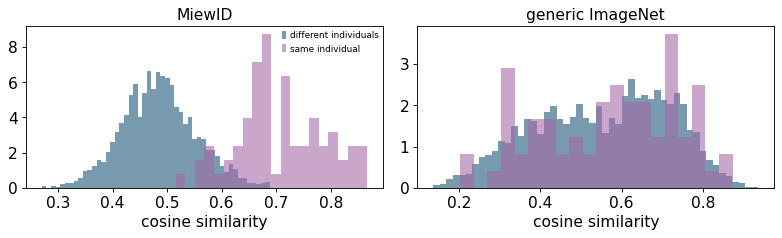

In [6]:
rows = []
for name, E, df in [("MiewID", Eg, g), ("generic ImageNet", Gg, g)]:
    S = E @ E.T
    rows.append({"descriptor": name,
                 "AUC identity": ov.tl.reid_pair_auc(S, df.identity),
                 "AUC site (background)": ov.tl.reid_pair_auc(S, df.site),
                 "AUC camera mode": ov.tl.reid_pair_auc(S, df.view)})
print("gallery images")
display(pd.DataFrame(rows).round(3))

def same_diff(S, y):
    iu = np.triu_indices(len(y), 1)
    same = np.asarray(y)[iu[0]] == np.asarray(y)[iu[1]]
    return S[iu][same], S[iu][~same]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (name, E) in zip(axes, [("MiewID", Eg), ("generic ImageNet", Gg)]):
    s1, s0 = same_diff(E @ E.T, g.identity)
    ax.hist(s0, 50, density=True, alpha=.6, label="different individuals")
    ax.hist(s1, 20, density=True, alpha=.6, label="same individual")
    ax.set_title(name); ax.set_xlabel("cosine similarity")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

The generic ImageNet features hardly separate individuals (identity AUC close
to 0.5) but strongly separate day from night shots: they describe the
picture, not the animal. MiewID separates individuals well, with a much
weaker camera-mode effect left over.

### Fusing descriptors

`reid_fuse_similarity` z-scores each similarity matrix (off-diagonal values)
so different descriptors share a scale, and takes a weighted mean. Weights
should come from data: `AUC − 0.5` on the labelled gallery, as the docstring
suggests. Equal weights let a useless descriptor dilute a good one.

In [7]:
auc_m = ov.tl.reid_pair_auc(Eg @ Eg.T, g.identity)
auc_e = ov.tl.reid_pair_auc(Gg @ Gg.T, g.identity)
w = [max(auc_m - 0.5, 1e-3), max(auc_e - 0.5, 1e-3)]
F_w = ov.tl.reid_fuse_similarity([Eg @ Eg.T, Gg @ Gg.T], weights=w)
F_eq = ov.tl.reid_fuse_similarity([Eg @ Eg.T, Gg @ Gg.T])
print(f"weights from AUC-0.5: {np.round(np.array(w) / sum(w), 3)}")
print(f"gallery AUC  MiewID {auc_m:.3f} | fused, AUC weights {ov.tl.reid_pair_auc(F_w, g.identity):.3f}"
      f" | fused, equal weights {ov.tl.reid_pair_auc(F_eq, g.identity):.3f}")

weights from AUC-0.5: [0.94 0.06]
gallery AUC  MiewID 0.983 | fused, AUC weights 0.979 | fused, equal weights 0.879


With AUC-derived weights the generic descriptor contributes almost nothing,
so fusion does no harm; with equal weights it drags the AUC down. With two
*good* re-ID descriptors (e.g. MiewID + MegaDescriptor) the same rule lets
the fusion gain. From here on we use MiewID alone.

### Camera-mode centring

Day and night photos of the same animal are pulled apart by a shared mode
shift. `reid_view_center` removes half of each mode's mean offset. It is
applied jointly to gallery and queries — **both must carry the mode label**
(it is usually in the camera-trap metadata) — and kept only if the gallery
AUC improves.

In [8]:
A = ov.tl.reid_view_center(np.vstack([Eg, Eq]), np.r_[g.view, q.view], strength=0.5)
Cg, Cq = A[:len(g)], A[len(g):]
auc_c = ov.tl.reid_pair_auc(Cg @ Cg.T, g.identity)
print(f"gallery identity AUC: raw {auc_m:.3f} -> mode-centred {auc_c:.3f}")
print(f"gallery camera-mode AUC: raw {ov.tl.reid_pair_auc(Eg @ Eg.T, g.view):.3f}"
      f" -> centred {ov.tl.reid_pair_auc(Cg @ Cg.T, g.view):.3f}")

gallery identity AUC: raw 0.983 -> mode-centred 0.988
gallery camera-mode AUC: raw 0.723 -> centred 0.594


### A reference-supervised projection?

`reid_fit_projection` fits PCA + shrinkage LDA on the gallery, i.e. a linear
map that maximises between-individual over within-individual scatter. It is
trained on *these* animals, so it is validated on **held-out individuals**
(like new animals among the queries): use it only if the held-out AUC rises.
`reference_oof` gives cross-fitted gallery coordinates (each image projected
by a model that never saw its individual), which is what the open-set
simulation needs if the projection is used.

In [9]:
pj = ov.tl.reid_fit_projection(Cg, g.identity)
print(f"held-out individuals: AUC raw {pj['heldout_auc_raw']:.3f}  projected {pj['heldout_auc_proj']:.3f}"
      f"  (median {pj['median_images_per_identity']:.0f} images / individual)")
use_projection = pj["heldout_auc_proj"] > pj["heldout_auc_raw"]
print("use projection:", use_projection)

held-out individuals: AUC raw 0.995  projected 0.968  (median 3 images / individual)
use projection: False


With three photos per individual the within-individual scatter is poorly
estimated and the projection does not generalise to unseen animals, so it is
not used. (The pipeline below applies the same rule, and additionally asks for
a median of ≥ 3 images per individual.)

## 3. Candidate pairs and local geometric verification

`reid_candidate_pairs` lists, for each query, its top-*k* neighbours under
the global similarity (with rank and reciprocity). `reid_local_verify` then
extracts SIFT keypoints (central `crop` to drop the image border, where only
background lives after a detector crop), matches each candidate pair with
the ratio test and RANSAC, runs the same matcher on random **null** pairs and
accepts a pair when its inlier count exceeds the null's 99.5 % quantile.

In [10]:
Sq = Cq @ Cq.T
pairs = ov.tl.reid_candidate_pairs(Sq, k=10)
y = q.identity.to_numpy()
same = y[pairs["first"]] == y[pairs["second"]]
n_true = int(sum(c * (c - 1) // 2 for c in q.identity.value_counts()))
print(f"{len(pairs)} candidate pairs (of {len(q) * (len(q) - 1) // 2}); "
      f"they contain {same.sum()} of the {n_true} same-individual pairs")
pairs.head()

382 candidate pairs (of 1540); they contain 40 of the 40 same-individual pairs


,first,second,sim,best_rank,reciprocal
0,0,10,0.527067,5,False
1,0,17,0.522318,7,False
2,0,19,0.550543,3,True
3,0,23,0.540415,4,False
4,0,26,0.575510,0,False


reid_local_verify: features for 56 images in 1s


reid_local_verify: 382 pairs + 300 null pairs in 1s; null inliers median 2, cut 10; accepted 41
inlier cut from the null: 10
accepted 41 pairs: 40 same individual, 1 different; missed same-individual candidates: 0


inliers                                              \
                  count   mean    std   min   25%   50%   75%   max   
truth                                                                 
different         342.0   3.00   2.31   0.0   0.0   4.0   4.0  13.0   
same individual    40.0  35.02  11.62  14.0  28.0  35.5  40.0  71.0   

                inlier_frac                                          
                      count  mean   std  min   25%   50%   75%  max  
truth                                                                
different             342.0  0.45  0.37  0.0  0.00  0.54  0.71  1.0  
same individual        40.0  0.91  0.06  0.8  0.86  0.93  0.96  1.0

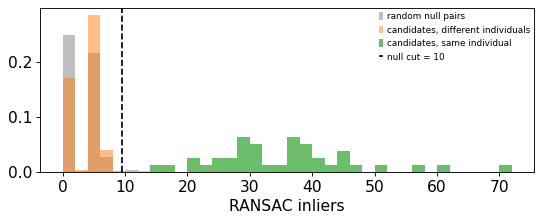

In [11]:
ver = ov.tl.reid_local_verify(q.path, pairs, image_root=IMG, crop=0.8, n_jobs=1, n_null=300)
cut = ver.attrs["inlier_cut"]
null = ver.attrs["null_inliers"]
acc = ver["accepted"].to_numpy()
print(f"inlier cut from the null: {cut:.0f}")
print(f"accepted {acc.sum()} pairs: {np.sum(acc & same)} same individual, {np.sum(acc & ~same)} different;"
      f" missed same-individual candidates: {np.sum(~acc & same)}")
# the verified table is an ordinary DataFrame: summarise inliers by (hidden) truth
display(ver.assign(truth=np.where(same, "same individual", "different"))
           .groupby("truth")[["inliers", "inlier_frac"]].describe().round(2))

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.arange(0, ver["inliers"].max() + 3, 2)
ax.hist(null, bins, alpha=.5, density=True, color="0.5", label="random null pairs")
ax.hist(ver["inliers"][~same], bins, alpha=.5, density=True, color="tab:orange",
        label="candidates, different individuals")
ax.hist(ver["inliers"][same], bins, alpha=.7, density=True, color="tab:green",
        label="candidates, same individual")
ax.axvline(cut, color="k", ls="--", label=f"null cut = {cut:.0f}")
ax.set_xlabel("RANSAC inliers"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The verified inlier counts are bimodal: different individuals give a few
accidental inliers — as many as random pairs — while photos of the same
animal give tens. The cut is read off the null, not chosen by eye (with
300 null pairs it is 10; the pipeline below uses 1000 and gets 7 — the
99.5 % quantile of a few hundred values is itself noisy). Below are the
inlier matches of the best same-individual and the best different-individual
candidate, drawn with plain OpenCV on the full frame (no crop).

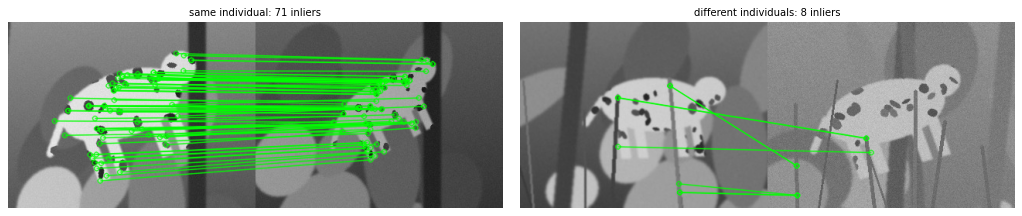

In [12]:
def draw_inliers(i, j, ax, title):
    a, b = (cv2.imread(os.path.join(IMG, q.path[k]), cv2.IMREAD_GRAYSCALE) for k in (i, j))
    sift = cv2.SIFT_create(1024)
    k1, d1 = sift.detectAndCompute(a, None)
    k2, d2 = sift.detectAndCompute(b, None)
    good = [m[0] for m in cv2.BFMatcher().knnMatch(d1, d2, k=2)
            if len(m) == 2 and m[0].distance < 0.75 * m[1].distance]
    keep = []
    if len(good) >= 4:
        _, mask = cv2.findHomography(np.float32([k1[m.queryIdx].pt for m in good]),
                                     np.float32([k2[m.trainIdx].pt for m in good]), cv2.RANSAC, 3.0)
        keep = [m for m, ok in zip(good, mask.ravel()) if ok]
    vis = cv2.drawMatches(a, k1, b, k2, keep, None, matchColor=(0, 255, 0), flags=2)
    ax.imshow(vis, cmap="gray"); ax.axis("off"); ax.set_title(f"{title}: {len(keep)} inliers", fontsize=9)

best_same = ver[same].sort_values("inliers").iloc[-1]
best_diff = ver[~same].sort_values("inliers").iloc[-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
draw_inliers(int(best_same["first"]), int(best_same["second"]), axes[0], "same individual")
draw_inliers(int(best_diff["first"]), int(best_diff["second"]), axes[1], "different individuals")
plt.tight_layout(); plt.show()

## 4. How many individuals? Choosing the cut from the reference

The labelled gallery is our only source of truth at analysis time.
`reid_select_threshold` repeatedly samples gallery individuals into a set the
size of the query batch, clusters it (average linkage) at each candidate
cosine cut and scores ARI and abundance error against the gallery labels.
Because this is a simulation, we can also check it against the *query*
truth, which no method sees.

selected cut 0.621 (simulated ARI 0.893, abundance error 0.14)


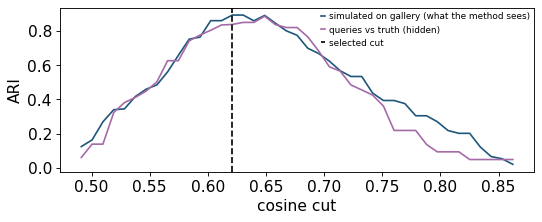

In [13]:
Sg = Cg @ Cg.T
sel = ov.tl.reid_select_threshold(Sg, g.identity, n_images=len(q), n_rep=5)
tab = sel["table"]
print(f"selected cut {sel['threshold']:.3f} (simulated ARI {sel['ari']:.3f}, "
      f"abundance error {sel['abundance_error']:.2f})")

def score(labels, truth=q.identity):
    k = len(set(labels))
    return {"ARI": round(adjusted_rand_score(truth, labels), 3), "individuals": k,
            "true": truth.nunique(), "abundance error": round(abs(k - truth.nunique()) / truth.nunique(), 3)}

real = [score(ov.tl.reid_open_set_cluster(Sq, threshold=t, method="agglomerative", log=None)["labels"])
        for t in tab.threshold]
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(tab.threshold, tab.ari, label="simulated on gallery (what the method sees)")
ax.plot(tab.threshold, [r["ARI"] for r in real], label="queries vs truth (hidden)")
ax.axvline(sel["threshold"], color="k", ls="--", label="selected cut")
ax.set_xlabel("cosine cut"); ax.set_ylabel("ARI"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The ARI curve simulated on the gallery peaks close to where the real
(hidden) query ARI peaks, so the reference tells us where to cut without
looking at the answer. Note how narrow the good range is: a cut 0.05 too low
merges individuals, 0.05 too high splits them.

### The full open-set partition

`reid_open_set_cluster` does this calibration jointly for the attach cut, the
cluster cut, the clustering method (average linkage vs HDBSCAN) and the
attach rule (single images vs whole clusters), on pseudo-gallery /
pseudo-query splits of the reference. Verified pairs enter as must-links.

In [14]:
acc_pairs = ver[ver["accepted"]]

def broken(labels):
    """Accepted verified pairs that ended up with different labels (needs no truth)."""
    lab = np.asarray(labels)
    return int(np.sum(lab[acc_pairs["first"].to_numpy()] != lab[acc_pairs["second"].to_numpy()]))

gal = dict(gallery_labels=g.identity)
runs = {}
runs["global similarity only"] = ov.tl.reid_open_set_cluster(
    Eq @ Eq.T, sim_qg=Eq @ Eg.T, sim_gg=Eg @ Eg.T, **gal, log=None)
runs["+ verified must-links"] = ov.tl.reid_open_set_cluster(
    Eq @ Eq.T, sim_qg=Eq @ Eg.T, sim_gg=Eg @ Eg.T, verified=ver, **gal, log=None)
runs["+ mode centring + verified"] = ov.tl.reid_open_set_cluster(
    Sq, sim_qg=Cq @ Cg.T, sim_gg=Sg, verified=ver, **gal)

def table(runs):
    return pd.DataFrame({k: {**score(r["labels"]), "method / attach": f"{r['method']}/{r['attach_mode']}",
                             "attached": r["n_attached"], "broken must-links": broken(r["labels"])}
                         for k, r in runs.items()}).T

table(runs)

reid_open_set_cluster: iter 0 sim(u=0.50, m=3.0) -> hdbscan/image t=nan a=0.6767 simARI=0.912 simAbErr=0.09; real: 26 individuals, 12 known
reid_open_set_cluster: mode=reference-simulation method=hdbscan/image threshold=nan attach_threshold=0.6767 attached=25/56 individuals=26


,ARI,individuals,true,abundance error,method / attach,attached,broken must-links
global similarity only,0.831,29,28,0.036,hdbscan/image,21,8
+ verified must-links,0.886,25,28,0.107,hdbscan/image,25,0
+ mode centring + verified,0.951,26,28,0.071,hdbscan/image,25,1


Read-out against the truth: ARI, the predicted vs true number of
individuals, and the abundance error. `attached` counts query photos that
received a catalogued identity (the truth is the number of query photos of
catalogued animals, printed below).

The last column is a **diagnostic that needs no truth**: how many accepted
verified pairs ended up under *different* labels. Verified pairs enter as
must-link components. When any member of a component clears the attach
cut, the **whole component** takes the gallery identity of its best-scoring
member (in both attach modes), so the attach cut can no longer name one
photo of a verified pair and declare its partner a new animal. The
component is then clustered with its photos at maximal similarity. HDBSCAN
or average linkage usually keeps them together, but can still leave a
pair apart when the rest of the evidence disagrees. A count of 0 is
therefore expected, and any remaining split pair is worth looking at (next
cell). Without the verified pairs (first row) the count is high: global
similarity alone splits several pairs that the spot patterns confirm.

In [15]:
r = runs["+ mode centring + verified"]
lab = np.asarray(r["labels"])
split = acc_pairs[lab[acc_pairs["first"].to_numpy()] != lab[acc_pairs["second"].to_numpy()]]
print("split verified pairs with the defaults:")
display(split[["first", "second", "sim", "inliers", "inlier_frac"]])
# the truth (hidden from the method) for these pairs:
print("same individual?", [bool(v) for v in (q.identity.to_numpy()[split["first"]] == q.identity.to_numpy()[split["second"]])])

split verified pairs with the defaults:


,first,second,sim,inliers,inlier_frac
328,35,38,0.520744,13,0.764706


same individual? [False]


With mode centring, one verified pair is left split. It is a weak one: its
inlier count is just above the null cut, and its inlier fraction is lower
than that of any confirmed pair in the summary above. The
truth shows it is the single *false* verified pair (two different new
animals), so the clustering was right to overrule it. The truth-free
reading is to treat a split pair near the inlier cut as doubtful
verification. A split pair with many inliers would point to a partition
that ignores the verified pairs.

The calibration chose `attach_mode="image"` (verified components, or single
photos, are attached one by one; the rest is clustered). For comparison,
`attach_mode="cluster"` clusters all queries first and attaches whole
clusters:

In [16]:
runs["+ mode centring + verified, cluster attach"] = ov.tl.reid_open_set_cluster(
    Sq, sim_qg=Cq @ Cg.T, sim_gg=Sg, verified=ver, attach_mode="cluster", **gal)
print("query photos of catalogued individuals:", int(q.known.sum()), "of", len(q))
table(runs)

reid_open_set_cluster: iter 0 sim(u=0.50, m=3.0) -> hdbscan/cluster t=nan a=0.6488 simARI=0.865 simAbErr=0.04; real: 25 individuals, 13 known
reid_open_set_cluster: mode=reference-simulation method=hdbscan/cluster threshold=nan attach_threshold=0.6488 attached=30/56 individuals=25
query photos of catalogued individuals: 27 of 56


,ARI,individuals,true,abundance error,method / attach,attached,broken must-links
global similarity only,0.831,29,28,0.036,hdbscan/image,21,8
+ verified must-links,0.886,25,28,0.107,hdbscan/image,25,0
+ mode centring + verified,0.951,26,28,0.071,hdbscan/image,25,1
"+ mode centring + verified, cluster attach",0.896,25,28,0.107,hdbscan/cluster,30,1


- **Global similarity alone** already recovers most of the partition
  (ARI ≈ 0.83, 29 vs 28 animals), but splits 8 verified pairs.
- **Verified must-links** remove those splits and raise the ARI (≈ 0.89).
  **Mode centring** on top gives the best result (ARI ≈ 0.95, 26 vs 28
  animals, abundance error 7 %). Within catalogued animals the partition is
  perfect (next cell).
- The default image-level attachment names 25 query photos. All are
  catalogued animals (there are 27 such photos), so none of the new animals
  is absorbed into the catalogue.
- `attach_mode="cluster"` is a valid alternative, but on this batch it is
  worse (ARI ≈ 0.90): it attaches 30 photos, more than the 27 photos of
  catalogued animals, so some new animals were given a catalogued name. The
  reference simulation preferred image-level attachment too (table below).

The `calibration` table is what the reference simulation saw: for each
clustering method, the best simulated ARI and abundance error, and the
objective that decided between them.

In [17]:
r = runs["+ mode centring + verified"]
kn = q.known.to_numpy()
print("ARI within catalogued animals:", round(adjusted_rand_score(q.identity[kn], r["labels"][kn]), 3),
      "| within new animals:", round(adjusted_rand_score(q.identity[~kn], r["labels"][~kn]), 3))
# what the reference simulation compared (best objective per method / attach rule)
cal = r["calibration"]
cal.loc[cal.groupby(["method", "attach_mode"])["objective"].idxmax(),
        ["method", "attach_mode", "threshold", "attach_threshold", "ari", "abundance_error", "objective"]].round(3)

ARI within catalogued animals: 1.0 | within new animals: 0.929


,method,attach_mode,threshold,attach_threshold,ari,abundance_error,objective
713,agglomerative,cluster,0.640,0.649,0.869,0.073,0.851
2842,agglomerative,image,0.612,0.742,0.884,0.042,0.874
3461,hdbscan,cluster,NaN,0.649,0.865,0.042,0.855
3506,hdbscan,image,NaN,0.677,0.912,0.094,0.888


### Without any reference

When no catalogue exists (a first survey), there is nothing to simulate on.
The accepted verified pairs then serve as pseudo-labels: the method and cut
are those that best reproduce held-out verified pairs (`mode='verified-pairs'`).
Without verification, the only remaining choice is HDBSCAN.

In [18]:
noref = {"verified-pair calibration": ov.tl.reid_open_set_cluster(Sq, verified=ver),
         "HDBSCAN, no verification": ov.tl.reid_open_set_cluster(Sq, log=None)}
pd.DataFrame({k: {**score(r["labels"]), "mode": r["mode"], "method": r["method"]}
              for k, r in noref.items()}).T

reid_open_set_cluster: mode=verified-pairs method=agglomerative/image threshold=0.6481 attach_threshold=None attached=0/56 individuals=28


,ARI,individuals,true,abundance error,mode,method
verified-pair calibration,1.0,28,28,0.0,verified-pairs,agglomerative
"HDBSCAN, no verification",0.896,25,28,0.107,hdbscan,hdbscan


## 5. One call: `reid_pipeline`

In practice, run `reid_pipeline` once per image subset (one species, one
population). It embeds the queries and the gallery (and with several
`backbones` screens and fuses them on a gallery sample — we pass MiewID only,
because no second re-ID backbone is cached here), applies camera-mode
centring and the projection only when they raise the held-out gallery AUC,
verifies the top-*k* candidate pairs and calls `reid_open_set_cluster`.
Every decision is written to `report`. It caches embeddings in `cache_dir`,
so the extra calls further down are cheap.

In [19]:
t = time.time()
kw = dict(image_root=IMG, backbones=("miewid",), verify_crop=0.8, n_workers=1,
          cache_dir=f"{CACHE}/pipeline", prefix="spot")
ref = dict(reference_paths=g.path, reference_labels=g.identity, query_views=q.view, reference_views=g.view)
res = ov.tl.reid_pipeline(q.path, **ref, **kw)
print(f"{time.time() - t:.0f} s")
print(score(res["labels"]), "| broken must-links:", broken(res["labels"]))
pd.Series(res["report"], dtype=object).to_frame("decision / diagnostic")

Building Model Backbone for efficientnetv2_rw_m model
config.model_name efficientnetv2_rw_m
model_name efficientnetv2_rw_m
final_in_features 2152


reid_embed: 56/56 images, 78s, 1.40 s/img (1 workers)


reid_embed: 72/72 images, 105s, 1.46 s/img (1 workers)
reid_pipeline[spot]: view_center=True projection=False


reid_local_verify: features for 56 images in 1s


reid_local_verify: 382 pairs + 1000 null pairs in 1s; null inliers median 4, cut 7; accepted 41


reid_open_set_cluster: iter 0 sim(u=0.50, m=3.0) -> hdbscan/image t=nan a=0.6767 simARI=0.912 simAbErr=0.09; real: 26 individuals, 12 known
reid_open_set_cluster: mode=reference-simulation method=hdbscan/image threshold=nan attach_threshold=0.6767 attached=25/56 individuals=26
reid_pipeline[spot]: 26 individuals from 56 images (25 images matched to known identities)
195 s
{'ARI': 0.951, 'individuals': 26, 'true': 28, 'abundance error': 0.071} | broken must-links: 1


,decision / diagnostic
n_query,56
sec_per_image_miewid,1.401
n_reference_used,72
n_reference_identities,24
view_center_auc,"(0.9829, 0.9883)"
view_center,True
projection_auc,"(0.9955, 0.968)"
median_images_per_identity,3.0
projection,False
verified_accepted,41


In [20]:
# open_set_kwargs pass straight to reid_open_set_cluster (here: the cluster-attach comparison)
res_c = ov.tl.reid_pipeline(q.path, **ref, **kw, open_set_kwargs={"attach_mode": "cluster"}, log=None)
print("cluster attach:", score(res_c["labels"]), "| broken must-links:", broken(res_c["labels"]))
res0 = ov.tl.reid_pipeline(q.path, **kw, log=None)            # no reference at all
print("no reference  :", score(res0["labels"]), "| mode:", res0["report"]["mode"])
pd.DataFrame({"truth": q.identity, "with reference": res["labels"], "no reference": res0["labels"]}).head(8)

Building Model Backbone for efficientnetv2_rw_m model
config.model_name efficientnetv2_rw_m
model_name efficientnetv2_rw_m


final_in_features 2152


cluster attach: {'ARI': 0.896, 'individuals': 25, 'true': 28, 'abundance error': 0.107} | broken must-links: 1
Building Model Backbone for efficientnetv2_rw_m model
config.model_name efficientnetv2_rw_m
model_name efficientnetv2_rw_m
final_in_features 2152


no reference  : {'ARI': 1.0, 'individuals': 28, 'true': 28, 'abundance error': 0.0} | mode: verified-pairs


,truth,with reference,no reference
0,animal00,spot_0,spot_19
1,animal01,spot_1,spot_0
2,animal01,spot_1,spot_0
3,animal01,spot_1,spot_0
4,animal02,spot_12,spot_13
5,animal03,spot_2,spot_7
6,animal03,spot_2,spot_7
7,animal04,spot_3,spot_15


- The pipeline made the same decisions as the step-by-step analysis and
  wrote down why: mode centring kept (gallery AUC 0.983 → 0.988), projection
  rejected (held-out AUC 0.996 → 0.968), 41 verified pairs, reference
  simulation with its simulated ARI.
- The default reproduces the step-by-step result (ARI ≈ 0.95) with 0
  verified pairs split by the attach step (the single split pair is the
  doubtful one discussed above). The cluster-attach comparison passed
  through `open_set_kwargs` is again lower (≈ 0.90).
- **Without a catalogue** the verified-pair calibration is perfect on this
  batch. That is not a general ranking: here the spot patterns are planar
  and sharp, so verification is almost error-free (40 of 40 true pairs, one
  false). The catalogue adds what the label-free route cannot: the *name* of
  each re-sighted animal, and a fall-back for photos that cannot be verified
  (non-planar markings, low resolution).

The labels are arbitrary names (`spot_0`, `spot_1`, …); only the grouping
matters, and the number of distinct labels is the abundance estimate.

## 6. Pitfalls

### 6a. A generic descriptor clusters scenes, not animals

The same open-set procedure on the generic ImageNet features:

In [21]:
r_gen = ov.tl.reid_open_set_cluster(Gq @ Gq.T, sim_qg=Gq @ Gg.T, gallery_labels=g.identity,
                                    sim_gg=Gg @ Gg.T, log=None)
r_gen0 = ov.tl.reid_open_set_cluster(Gq @ Gq.T, log=None)
print("generic, with gallery :", score(r_gen["labels"]))
print("generic, HDBSCAN      :", score(r_gen0["labels"]))
print("ARI of the generic HDBSCAN clusters vs camera mode:",
      round(adjusted_rand_score(q.view, r_gen0["labels"]), 3),
      "| vs site:", round(adjusted_rand_score(q.site, r_gen0["labels"]), 3))

generic, with gallery : {'ARI': -0.029, 'individuals': 32, 'true': 28, 'abundance error': 0.143}
generic, HDBSCAN      : {'ARI': -0.01, 'individuals': 30, 'true': 28, 'abundance error': 0.071}
ARI of the generic HDBSCAN clusters vs camera mode: 0.063 | vs site: 0.073


Near-zero ARI: no cut can rescue a descriptor whose similarities are not
about individuals. Check `reid_pair_auc` against identity *and* against
nuisance labels before clustering anything.

### 6b. Hand-picked cuts: silhouette, "reasonable" cosine values, inlier counts

A common shortcut is to choose the number of clusters by the silhouette
score, or to cut at a round cosine value. Neither knows what an individual
looks like in *this* descriptor.

In [22]:
D = np.clip(1 - Sq, 0, None); D = (D + D.T) / 2; np.fill_diagonal(D, 0)
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
Z = linkage(squareform(D, checks=False), "average")
sil = [(silhouette_score(D, fcluster(Z, k, "maxclust"), metric="precomputed"), k)
       for k in range(2, len(q) - 1)]
k_sil = max(sil)[1]
print("silhouette choice:", score(fcluster(Z, k_sil, "maxclust")))
for t_hand in (0.5, 0.6, 0.7, 0.8):
    print(f"hand cut {t_hand}:", score(ov.tl.reid_open_set_cluster(Sq, threshold=t_hand,
                                                               method="agglomerative", log=None)["labels"]))
print("reference-selected cut:", score(ov.tl.reid_open_set_cluster(Sq, threshold=sel["threshold"],
                                                                  method="agglomerative", log=None)["labels"]))

silhouette choice: {'ARI': 0.833, 'individuals': 26, 'true': 28, 'abundance error': 0.071}
hand cut 0.5: {'ARI': 0.138, 'individuals': 7, 'true': 28, 'abundance error': 0.75}
hand cut 0.6: {'ARI': 0.804, 'individuals': 27, 'true': 28, 'abundance error': 0.036}
hand cut 0.7: {'ARI': 0.638, 'individuals': 41, 'true': 28, 'abundance error': 0.464}
hand cut 0.8: {'ARI': 0.093, 'individuals': 54, 'true': 28, 'abundance error': 0.929}
reference-selected cut: {'ARI': 0.838, 'individuals': 30, 'true': 28, 'abundance error': 0.071}


The round cosine values land anywhere between "everything merged" (0.5:
7 animals) and "everything split" (0.8: 54 animals). The silhouette lands
close on this batch, but it is a purely geometric criterion: it gives every
singleton (12 of the 28 animals are seen once) a score of 0, has no notion of
what separates individuals in this descriptor, and cannot be checked without
labels — the reference simulation can, and is checked on the gallery. The
same applies to the verification step: linking photos whenever
they share "a few" RANSAC inliers, and taking connected components, chains
different animals together, because a handful of accidental inliers is what
random pairs produce (see the null histogram above).

In [23]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

def components(min_inl):
    m = ver["inliers"].to_numpy() > min_inl
    adj = csr_matrix((np.ones(m.sum()), (ver["first"][m], ver["second"][m])), shape=(len(q), len(q)))
    return connected_components(adj, directed=False)[1]

for c in (4, 6, cut):
    print(f"components of pairs with > {c:.0f} inliers:", score(components(c)))

components of pairs with > 4 inliers: {'ARI': 0.0, 'individuals': 1, 'true': 28, 'abundance error': 0.964}
components of pairs with > 6 inliers: {'ARI': 0.322, 'individuals': 16, 'true': 28, 'abundance error': 0.429}
components of pairs with > 10 inliers: {'ARI': 0.928, 'individuals': 27, 'true': 28, 'abundance error': 0.036}


At the null-calibrated cut the verified components are nearly pure but leave
every animal whose photos did not verify as a singleton; below it, chains
merge many animals. Verified pairs are best used as **must-links** inside a
calibrated clustering, as `reid_open_set_cluster` does.

### 6c. Overriding the pipeline: forcing the projection

The pipeline declined the LDA projection because it lowered the held-out
AUC (section 2). Forcing it (`projection="on"`) is a typical override — and
doing the same by hand with the projected gallery coordinates as `sim_gg`
is worse still: an LDA fitted on the gallery separates *its own* individuals
perfectly, so the reference simulation believes every cut is perfect.

In [24]:
r_on = ov.tl.reid_pipeline(q.path, **ref, **kw, projection="on", log=None)
print(f"pipeline, projection forced : {score(r_on['labels'])} | simulated ARI {r_on['report']['sim_ari']}")
print(f"pipeline, projection by rule: {score(res['labels'])} | simulated ARI {res['report']['sim_ari']}")

pj_c = ov.tl.reid_fit_projection(Cg, g.identity)
Pq, Pg = pj_c["transform"](Cq), pj_c["transform"](Cg)
print("gallery AUC, in-sample projected:", round(ov.tl.reid_pair_auc(Pg @ Pg.T, g.identity), 3),
      "| cross-fitted (reference_oof):", round(ov.tl.reid_pair_auc(pj_c["reference_oof"] @ pj_c["reference_oof"].T,
                                                                     g.identity), 3))
r_in = ov.tl.reid_open_set_cluster(Pq @ Pq.T, sim_qg=Pq @ Pg.T, sim_gg=Pg @ Pg.T, verified=ver,
                                   **gal, log=None)
print(f"by hand, in-sample sim_gg   : {score(r_in['labels'])} | simulated ARI "
      f"{r_in['history'].iloc[-1]['sim_ari']:.3f}")

Building Model Backbone for efficientnetv2_rw_m model
config.model_name efficientnetv2_rw_m
model_name efficientnetv2_rw_m
final_in_features 2152


pipeline, projection forced : {'ARI': 0.711, 'individuals': 24, 'true': 28, 'abundance error': 0.143} | simulated ARI 0.6798
pipeline, projection by rule: {'ARI': 0.951, 'individuals': 26, 'true': 28, 'abundance error': 0.071} | simulated ARI 0.9118
gallery AUC, in-sample projected: 1.0 | cross-fitted (reference_oof): 0.968


by hand, in-sample sim_gg   : {'ARI': 0.627, 'individuals': 21, 'true': 28, 'abundance error': 0.25} | simulated ARI 1.000


Forcing the projection lowers the real ARI (≈ 0.71 vs ≈ 0.95), and the
pipeline's own diagnostic warned about it: the simulated ARI dropped as well,
because the pipeline correctly simulates on cross-fitted coordinates. Fitting
the projection by hand and feeding the **in-sample** gallery similarities to
the simulation is the dangerous version: the gallery AUC becomes 1.0, the
simulation reports a perfect ARI, and the real partition is the worst of all.
Any step fitted on the gallery must be evaluated on individuals it has not
seen — which is what `reference_oof` and the held-out AUC are for.

The pipeline also refuses another override seen in practice — camera-mode
centring when the queries carry no mode label (they would all form one
"unknown" group, shifted as a block relative to the gallery):

In [25]:
r_nov = ov.tl.reid_pipeline(q.path, reference_paths=g.path, reference_labels=g.identity,
                            reference_views=g.view, view_center="on", **kw, log=None)
print("no query view labels, view_center='on' -> centring applied:", r_nov["report"]["view_center"])

Building Model Backbone for efficientnetv2_rw_m model
config.model_name efficientnetv2_rw_m
model_name efficientnetv2_rw_m
final_in_features 2152


no query view labels, view_center='on' -> centring applied: False


Use the labels as returned, and change a decision only with evidence from
the labelled reference (the `report` and `calibration` tables), never from the
shape of the query scores alone.

## Summary

- Use a re-ID backbone and check it with `reid_pair_auc` against identity
  **and** nuisance labels (site, camera mode); generic features cluster scenes.
- Verify the top-*k* candidate pairs geometrically (`reid_local_verify`) and
  let a random-pair null set the inlier cut.
- Choose every cut from data: simulation on the labelled reference
  (`reid_select_threshold`, `reid_open_set_cluster`), or verified pairs as
  pseudo-labels when there is no reference.
- Check that the partition respects the verified pairs (a truth-free
  diagnostic). Pass the verified pairs and expect 0 split pairs; a split
  pair near the inlier cut is doubtful verification, one with many inliers
  means the partition ignores the verification.
- Keep optional steps (fusion, mode centring, projection) only when they
  raise held-out reference AUC — `reid_pipeline` does exactly this; do not
  override it without evidence from the reference, and never evaluate a
  gallery-fitted step on the gallery itself.

In [26]:
print(f"total runtime {time.time() - T0:.0f} s")

total runtime 522 s


## References

- Lowe, D. G. (2004). Distinctive image features from scale-invariant keypoints. *IJCV* 60, 91–110.
- Fischler, M. A. & Bolles, R. C. (1981). Random sample consensus. *Commun. ACM* 24, 381–395.
- Otarashvili, L. et al. (2024). Multispecies animal re-ID using a large community-curated dataset (MiewID). arXiv:2412.05174.
- Čermák, V., Picek, L., Adam, L. & Papafitsoros, K. (2024). WildlifeDatasets: an open-source toolkit for animal re-identification (MegaDescriptor). *WACV 2024*, 5953–5963.
- Tan, M. & Le, Q. (2021). EfficientNetV2: smaller models and faster training. *ICML 2021*.
- Schneider, S., Taylor, G. W., Linquist, S. & Kremer, S. C. (2019). Past, present and future approaches using computer vision for animal re-identification from camera trap data. *Methods Ecol. Evol.* 10, 461–470.
- Bolger, D. T., Morrison, T. A., Vance, B., Lee, D. & Farid, H. (2012). A computer-assisted system for photographic mark–recapture analysis. *Methods Ecol. Evol.* 3, 813–822.
- Hubert, L. & Arabie, P. (1985). Comparing partitions. *J. Classif.* 2, 193–218.
- Campello, R. J. G. B., Moulavi, D. & Sander, J. (2013). Density-based clustering based on hierarchical density estimates (HDBSCAN). *PAKDD 2013*.
- Rousseeuw, P. J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. *J. Comput. Appl. Math.* 20, 53–65.